# Анализ данных в Python. Финальный экзамен
Васина Дарья

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from rink import plot_rink

plt.rcParams["figure.dpi"] = 110

## Задача 1

Анализируем записи хоккейных матчей плей-офф НХЛ сезона 2025/2026. Рядом с ноутбуком должны лежать `NHL-playoffs-2026.xlsx` и `rink.py` (код для рисования площадки из задания).

Во всём ноутбуке «точными» бросками называем броски в створ ворот: события `shot-on-goal` и `goal` (гол - это тоже бросок в створ, вратарь его не отбил), «неточными» - `missed-shot`. Заблокированные броски (`blocked-shot`) в точные и неточные не входят: в пункте 8 условие называет точными только `shot-on-goal` и `goal`, неточными - `missed-shot`, а в пункте 10 долю точных считают среди незаблокированных бросков.

### (1) Загрузка данных

В файле есть безымянный первый столбец - это просто номер строки, который был сохранён при записи в Excel. Если оставить его как есть, получится 39 столбцов вместо 38 из примера, поэтому читаем его как индекс (`index_col=0`). Столбец `Date` сразу переводим в тип даты (`parse_dates`).

In [2]:
events = pd.read_excel("NHL-playoffs-2026.xlsx", index_col=0, parse_dates=["Date"])
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


**Предобработка: кодировка имён игроков.** В трёх фамилиях кодировка «поехала» (например, `Juraj SlafkovskÃ½` вместо `Juraj Slafkovský`): UTF-8 байты были прочитаны как cp1252. Исправляем это во всех столбцах с именами игроков функцией `fix_encoding`.

In [4]:
def fix_encoding(name: str) -> str:
  try:
    return name.encode("cp1252").decode("utf-8")
  except (UnicodeEncodeError, UnicodeDecodeError):
    return name

player_columns_all = [c for c in events.columns if "Player in the Event" in c or "Player on the Ice" in c or c.endswith("Goalie")]
events[player_columns_all] = events[player_columns_all].apply(lambda col: col.map(fix_encoding, na_action="ignore"))

[n for n in events["Player in the Event #1"].dropna().unique() if "Slafkovsk" in n or "Stützle" in n or "Bäck" in n]

['Juraj Slafkovský', 'Tim Stützle', 'Oskar Bäck']

### (2) Сводная таблица по играм

Последнее событие каждой игры - `game-end`, в нём уже лежит итоговый счёт (`Cumulated Away Score`, `Cumulated Home Score`) и номер последнего периода (`Period`). По номеру последнего периода определяем исход игры: 3 - `Final`, 4 - `Final/OT`, 5 - `Final/2OT` и так далее (`get_outcome`). Строим таблицу `games` с индексом `Game ID`.

Дополнительно проверим, что таблица согласована с исходными событиями: сумма всех итоговых счетов должна равняться числу событий `goal`, ничьих быть не должно (в плей-офф они невозможны), а `game-end` должен встречаться ровно один раз на игру.

In [5]:
def get_outcome(last_period: int) -> str:
  if last_period == 3:
    return "Final"
  if last_period == 4:
    return "Final/OT"
  return f"Final/{last_period - 3}OT"

game_end = events[events["Play Type"] == "game-end"].set_index("Game ID")
games = game_end[["Date", "Away Team", "Home Team", "Cumulated Away Score", "Cumulated Home Score"]].copy()
games.columns = ["Date", "Away Team", "Home Team", "Away Score", "Home Score"]
games["Outcome"] = game_end["Period"].map(get_outcome)
games = games.sort_index()

games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [6]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [7]:
print(f"Игр: {len(games)}")
print(f"game-end на игру ровно один раз: {game_end.index.is_unique}")
print(f"Сумма итоговых счетов: {games[['Away Score', 'Home Score']].sum().sum()}")
print(f"Событий goal: {(events['Play Type'] == 'goal').sum()}")
print(f"Ничьих: {(games['Away Score'] == games['Home Score']).sum()}")
games["Outcome"].value_counts()

Игр: 82
game-end на игру ровно один раз: True
Сумма итоговых счетов: 486
Событий goal: 486
Ничьих: 0


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

### (3) Функция `gameInfo`

- `gameInfo(gameId)` - достаёт строку игры из `games` и собирает описание в формате из задания: хозяева - гости (счёт хозяев - счёт гостей, исход, дата).

In [8]:
def gameInfo(gameId: int) -> str:
  game = games.loc[gameId]
  return f"{game['Home Team']} - {game['Away Team']} ({game['Home Score']} - {game['Away Score']}, {game['Outcome']}, {game['Date'].date()})"

gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [9]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

### (4) Число голов в игре

In [10]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
games["Total Score"].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

В среднем за игру забивается 5.93 гола (медиана 6, стандартное отклонение 2.26). Половина игр укладывается в диапазон от 5 до 7 голов, минимум - 1 гол, максимум - 15.

### (5) Гистограмма числа голов в игре

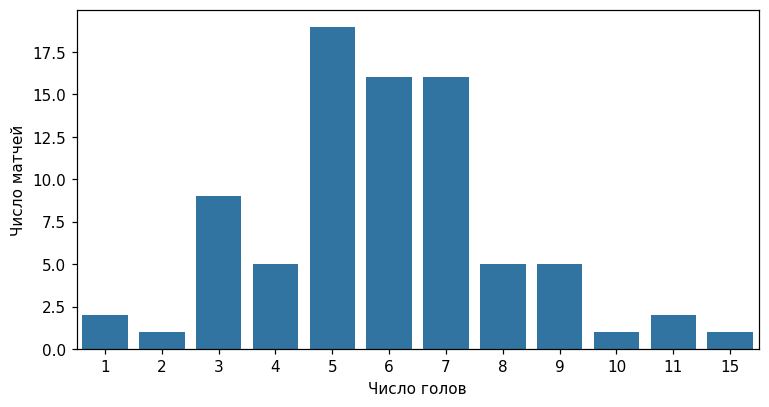

In [11]:
plt.figure(figsize=(8, 4))
sns.countplot(data=games, x="Total Score", color="tab:blue")
plt.xlabel("Число голов")
plt.ylabel("Число матчей")
plt.show()

In [12]:
print(f"Дисперсия: {games['Total Score'].var():.2f}")
print(f"Среднее: {games['Total Score'].mean():.2f}")
print(f"Игр с 5-7 голами: {games['Total Score'].between(5, 7).sum()} из {len(games)}")
print("Средний тотал без овертайма и с овертаймом:")
games.groupby(games["Outcome"] != "Final")["Total Score"].mean().round(2).rename({False: "основное время", True: "овертайм"})

Дисперсия: 5.11
Среднее: 5.93
Игр с 5-7 голами: 51 из 82
Средний тотал без овертайма и с овертаймом:


Outcome
основное время    6.10
овертайм          5.45
Name: Total Score, dtype: float64

Основная масса матчей приходится на 5-7 голов: 51 игра из 82 (62%), причём 5, 6 и 7 голов встречаются почти одинаково часто (19, 16 и 16 игр), поэтому мода (5 голов) выражена слабо и вершина получается плоской. Есть и небольшой вторичный пик на 3 голах (9 игр) с провалом на 4 голах (5 игр), но при 82 играх это вполне может быть случайностью. Среднее 5.93 и медиана 6 почти совпадают, поэтому распределение почти симметрично, но справа у него заметный хвост: было 4 матча с 10 и более голами (максимум - 15, это игра Colorado - Minnesota, 9 - 6), а слева - всего 3 матча, где забито не больше двух шайб.

Интересно, что дисперсия (5.1) близка к среднему (5.9). Для распределения Пуассона они совпадают: гол - редкое событие, и если считать, что голы забиваются независимо друг от друга с примерно постоянной интенсивностью, то именно такое распределение и ожидается. У нас дисперсия чуть меньше среднего, то есть разброс чуть более «сжатый», чем у чистого Пуассона.

Отдельно видно влияние овертайма: матчи, дошедшие до овертайма, в среднем менее результативны (5.45 гола против 6.10 в матчах, закончившихся в основное время) - что логично, ведь ничья к концу третьего периода чаще случается в играх, где голов было мало.

### (6) Самые нерезультативные и самые результативные игры

Берём игры, у которых `Total Score` равен минимуму и максимуму соответственно.

In [13]:
[gameInfo(i) for i in games.index[games["Total Score"] == games["Total Score"].min()]]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [14]:
[gameInfo(i) for i in games.index[games["Total Score"] == games["Total Score"].max()]]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Самые нерезультативные игры - две, в каждой всего по одному голу, и обе закончились победой 1 - 0 в овертайме (Montréal - Tampa Bay и Philadelphia - Pittsburgh). Самая результативная - Colorado - Minnesota (9 - 6, 15 голов) - прошла в основное время.

### (7) Число игроков, участвовавших в игре

Берём все столбцы с игроками на льду (шесть полевых слотов и вратарь у каждой из двух команд), собираем значения по игре в один массив, убираем пропуски и считаем число уникальных фамилий (`count_players`).

In [15]:
away_columns = [c for c in events.columns if c.startswith("Away Team's Player") or c == "Away Team's Goalie"]
home_columns = [c for c in events.columns if c.startswith("Home Team's Player") or c == "Home Team's Goalie"]
player_columns = away_columns + home_columns

def count_players(game_events: pd.DataFrame) -> int:
  players = pd.Series(game_events[player_columns].to_numpy().ravel()).dropna()
  return players.nunique()

player_count = events.groupby("Game ID")[player_columns].apply(count_players)
player_count.value_counts()

38    73
39     8
40     1
Name: count, dtype: int64

In [16]:
top_games = player_count[player_count == player_count.max()]
pd.DataFrame(
  {"Game Info": [gameInfo(i) for i in top_games.index], "Player Count": top_games.values},
  index=top_games.index,
)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


**Расхождение с примером.** Игра та же (`Montréal Canadiens - Buffalo Sabres (3 - 8)`), но получилось 40 игроков, а в примере из задания - 41. Лишняя единица берётся отсюда: если не выбрасывать пропуски, то `NaN` (пустой слот, когда на льду меньше игроков, чем слотов, или вратарь снят) считается ещё одним «игроком». Проверим это в данных: 

In [17]:
game_values = events.loc[events["Game ID"] == top_games.index[0], player_columns].to_numpy().ravel()
print(f"Уникальных значений вместе с NaN: {len(pd.unique(game_values))}")
print(f"Уникальных фамилий без NaN: {len(pd.unique(game_values[pd.notna(game_values)]))}")

Уникальных значений вместе с NaN: 41
Уникальных фамилий без NaN: 40


Так что 40 - это реальное число игроков (по 20 у каждой команды), а 41 - результат подсчёта пропуска как игрока. Содержательный вывод не меняется: игра с наибольшим числом игроков по обеим версиям одна и та же, а в большинстве игр участвует ровно 38 человек.

### (8) Расстояние до ворот для бросков

Расстояние считаем по формуле из условия (до ближайшей точки створа ворот). Какие ворота атакует команда, определяем по `Home Team's Defending Side`: бросок хозяев при `left` и гостей при `right` летит в правые ворота (`X = 89`), в остальных случаях - в левые (`X = -89`). Кто бросал, определяем сравнением `Team Making the Play` с `Home Team`.

- `get_shot_length(shots)` - принимает таблицу бросков и возвращает расстояние до ворот для каждого из них (векторно, без цикла по строкам).

In [18]:
SHOT_TYPES = ["shot-on-goal", "goal", "missed-shot"]

def get_shot_length(shots: pd.DataFrame) -> pd.Series:
  is_home = shots["Team Making the Play"] == shots["Home Team"]
  attacks_right = is_home == (shots["Home Team's Defending Side"] == "left")
  goal_x = np.where(attacks_right, 89, -89)
  dx = shots["X Coordinate on the Ice Rink"] - goal_x
  dy = (shots["Y Coordinate on the Ice Rink"].abs() - 3).clip(lower=0)
  return np.hypot(dx, dy)

is_shot = events["Play Type"].isin(SHOT_TYPES)
events["Shot Length"] = np.nan
events.loc[is_shot, "Shot Length"] = get_shot_length(events[is_shot])

events[is_shot][["Game ID", "Play Type", "Shot Length"]]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


**Вспомогательное: вратарь на льду непосредственно перед событием.** Дальше (в пунктах 9 и 21) понадобится знать, был ли в воротах вратарь в момент гола. Брать его из строки самого гола нельзя: состав на льду в строке события отражает ситуацию уже *после* события (после гола в пустые ворота вратарь возвращается в ворота; у победного гола в овертайме оба вратаря отсутствуют; после пропущенного гола вратаря могут сменить). Поэтому для каждой строки берём вратарей из предыдущего события той же игры (`groupby("Game ID").shift(1)`).

Это корректно, если события внутри игры лежат в хронологическом порядке, поэтому сначала проверим это.

In [19]:
print(f"Play ID растёт внутри каждой игры: {events.groupby('Game ID')['Play ID'].apply(lambda s: s.is_monotonic_increasing).all()}")

for side in ["Away", "Home"]:
  events[f"Previous {side} Goalie"] = events.groupby("Game ID")[f"{side} Team's Goalie"].shift(1)

Play ID растёт внутри каждой игры: True


### (9) Распределение длины точных и неточных бросков

Точных бросков (4623) заметно больше, чем неточных (2643), поэтому гистограммы по числу бросков сравнивать неудобно. Строим плотности: `stat="density"` и `common_norm=False` нормируют каждую группу отдельно.

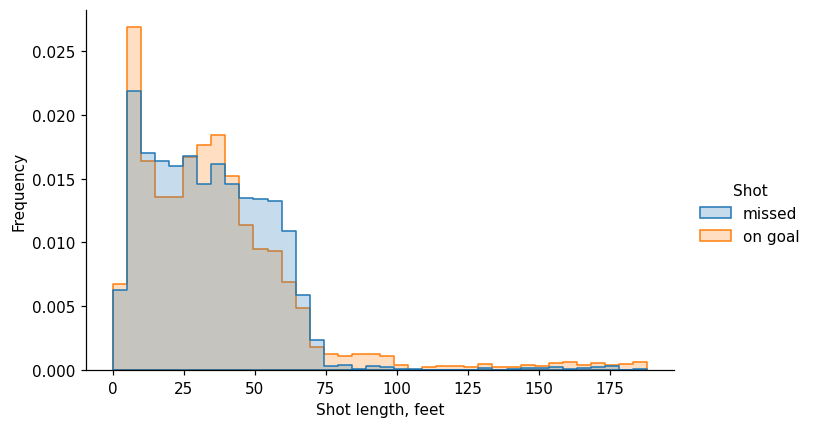

In [20]:
shots = events[is_shot].copy()
shots["Shot"] = np.where(shots["Play Type"] == "missed-shot", "missed", "on goal")

sns.displot(
  data=shots, x="Shot Length", hue="Shot", hue_order=["missed", "on goal"],
  stat="density", common_norm=False, binwidth=5, element="step",
  height=4, aspect=1.6,
)
plt.xlabel("Shot length, feet")
plt.ylabel("Frequency")
plt.show()

In [21]:
shots.groupby("Shot")["Shot Length"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.0,22.3,0.0,16.2,32.2,49.0,185.1
on goal,4623.0,36.2,30.0,0.0,15.0,31.8,47.0,188.2


**Что видно.** Основная часть распределений почти одинакова: основная масса бросков в обеих группах лежит в диапазоне примерно 5-55 футов, медианы практически совпадают (31.8 фута у точных против 32.2 у неточных), так что по расстоянию точный бросок от неточного в основной массе отличить нельзя. Проверим это: посчитаем долю точных бросков по диапазонам расстояния.

In [22]:
shots["On Goal"] = shots["Shot"] == "on goal"
shots["Distance Bin"] = pd.cut(shots["Shot Length"], [-0.1, 10, 20, 30, 40, 50, 60, 75, 100, 200])
shots.groupby("Distance Bin", observed=True)["On Goal"].agg(["mean", "count"]).rename(columns={"mean": "Share on goal", "count": "Shots"})

,Share on goal,Shots
Distance Bin,,
"(-0.1, 10.0]",0.676253,1217
"(10.0, 20.0]",0.607970,1079
"(20.0, 30.0]",0.619681,1128
"(30.0, 40.0]",0.670978,1237
"(40.0, 50.0]",0.624360,977
"(50.0, 60.0]",0.541502,759
"(60.0, 75.0]",0.559259,540
"(75.0, 100.0]",0.904110,146
"(100.0, 200.0]",0.874317,183


Доля точных бросков держится на уровне 54-68% на всём диапазоне до 75 футов (около 64% в среднем) и вблизи ворот не выше, чем на 30-40 футах. Но дальше 75 футов она резко подскакивает до 87-90%. Это и есть тот самый длинный хвост точных бросков: дальше 75 футов точных бросков 6.3% от всех точных, а неточных - всего 1.4%; дальше 100 футов - 3.5% против 0.9%.

**Почему так? Проверим гипотезы на данных.** Броски дальше 100 футов - это броски со своей половины площадки (все 183 такие события в данных лежат в `Play Zone` = `Defensive` или `Neutral`).

In [23]:
far = shots[shots["Shot Length"] > 100]
print(f"Бросков дальше 100 футов: {len(far)}, из них точных: {far['On Goal'].sum()}")
print(far[far["On Goal"]]["Period"].value_counts().sort_index().rename("Точные дальние броски по периодам").to_string())
print()
shots.groupby("Play Zone")["On Goal"].agg(["mean", "count"]).rename(columns={"mean": "Share on goal", "count": "Shots"})

Бросков дальше 100 футов: 183, из них точных: 160
Period
1    52
2    48
3    51
4     8
5     1



,Share on goal,Shots
Play Zone,,
Defensive,0.871951,164
Neutral,0.883495,206
Offensive,0.623260,6896


**Гипотеза 1: броски в пустые ворота.** Если соперник снял вратаря ради шестого полевого игрока, то лидирующая команда может забросить шайбу в пустые ворота с любого расстояния. Это объясняет часть хвоста, но только голов. Посмотрим на 17 голов с расстояния больше 100 футов.

In [24]:
far_goals = far[far["Play Type"] == "goal"].copy()
is_home_shooter = far_goals["Team Making the Play"] == far_goals["Home Team"]
far_goals["Lead After Goal"] = np.where(
  is_home_shooter,
  far_goals["Cumulated Home Score"] - far_goals["Cumulated Away Score"],
  far_goals["Cumulated Away Score"] - far_goals["Cumulated Home Score"],
)
far_goals["Goalie Before Goal"] = np.where(is_home_shooter, far_goals["Previous Away Goalie"], far_goals["Previous Home Goalie"])
print(f"Дальних голов в пустые ворота: {far_goals['Goalie Before Goal'].isna().sum()} из {len(far_goals)}")
far_goals[["Game ID", "Period", "Remaining Time", "Team Making the Play", "Lead After Goal", "Goalie Before Goal", "Shot Length"]].round(1)

Дальних голов в пустые ворота: 15 из 17


,Game ID,Period,Remaining Time,Team Making the Play,Lead After Goal,Goalie Before Goal,Shot Length
10308,2025030161,3,03:08,Minnesota Wild,5,NaN,116.1
10669,2025030162,3,00:50,Dallas Stars,2,NaN,162.0
12162,2025030166,3,00:15,Minnesota Wild,3,NaN,167.4
12532,2025030171,3,01:39,Vegas Golden Knights,2,Karel Vejmelka,132.7
14565,2025030176,3,03:36,Vegas Golden Knights,4,NaN,120.3
15320,2025030182,3,01:10,Anaheim Ducks,2,NaN,129.0
15676,2025030183,3,01:33,Anaheim Ducks,3,Connor Ingram,172.6
18662,2025030216,3,05:48,Buffalo Sabres,4,NaN,158.2
20945,2025030231,3,02:08,Colorado Avalanche,3,NaN,131.9
21289,2025030232,3,00:05,Colorado Avalanche,3,NaN,166.2


Все 17 дальних голов забиты в третьем периоде, в последние минуты (от 4 секунд до 5:48 до конца), командой, которая выигрывает с запасом в 2-5 шайб (в таблице счёт уже включает этот гол) - это классические голы в пустые ворота. Проверка по составам это подтверждает: в 15 из 17 случаев в предыдущем событии вратаря соперника на льду уже не было (в двух оставшихся играх 171 и 183 ворота, судя по данным, пустыми не были). Заодно видно, почему нельзя брать вратаря из строки самого гола: в ней он указан в 14 из 17 случаев, потому что после гола вратарь возвращается в ворота. Всего в плей-офф было 34 гола в пустые ворота - все в третьем периоде, не позже чем за 5:48 до конца.

Но этого недостаточно: в хвосте не 17 голов, а 160 точных бросков, и 143 из них - это бросок в створ, который отбил вратарь (в пустые ворота такого быть не может - шайба просто была бы голом). К тому же они распределены по периодам равномерно: 52, 48 и 51 в первом, втором и третьем периодах, а не в концовках матчей.

**Гипотеза 2: «отбор» событий (то, что не попало в створ, в бросок не превращается).** По правилам хоккея, бросок со своей половины площадки, который не попал в створ и ушёл за линию ворот соперника, обычно фиксируется как «проброс шайбы» (`icing`), а не как `missed-shot`. В данных таких остановок игры (`stoppage` с подтипом `icing`) 830. Тогда в записях бросков остаются преимущественно те дальние броски, которые всё-таки дошли до ворот и были отбиты вратарём или заброшены. Именно поэтому доля точных бросков со своей половины (87-88% в `Defensive` и `Neutral` зонах против 62% в `Offensive`) подозрительно высока - в реальности попасть с 150 футов в ворота шириной 6 футов намного труднее, чем с 20 футов. Эту гипотезу прямо по данным подтвердить нельзя (в записях просто нет информации о том, куда летела шайба, если игра была остановлена из-за проброса), но она согласуется со всеми наблюдениями: резким скачком доли точных бросков за 75 футов и равномерным распределением хвоста по периодам.

**Итог:** хвост образуют два механизма - голы в пустые ворота в конце игр (15 из 160 точных бросков дальше 100 футов) и дальние броски в створ со своей половины, которые попадают в записи только если шайба дошла до ворот (остальные 145).

### (10) Доля точных бросков среди всех незаблокированных

Для каждой пары (игра, команда) считаем число точных бросков (`shot-on-goal` и `goal`) и число всех незаблокированных бросков (плюс `missed-shot`). Их отношение - `Share of Shots on Goal`. Пар получается 164 = 82 игры × 2 команды.

In [25]:
numshots = shots.groupby(["Game ID", "Team Making the Play"])["On Goal"].agg(["sum", "count"])
numshots.columns = ["Shots on Goal", "Unblocked Shots"]
numshots["Share of Shots on Goal"] = numshots["Shots on Goal"] / numshots["Unblocked Shots"]

numshots["Share of Shots on Goal"]

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [26]:
numshots["Share of Shots on Goal"].describe().round(3)

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

In [27]:
# связь доли точных бросков с результатом: сравним долю в выигранных и проигранных командой играх
game_result = pd.concat([
  pd.DataFrame({"Game ID": games.index, "Team Making the Play": games["Away Team"].values, "Win": (games["Away Score"] > games["Home Score"]).values}),
  pd.DataFrame({"Game ID": games.index, "Team Making the Play": games["Home Team"].values, "Win": (games["Home Score"] > games["Away Score"]).values}),
]).set_index(["Game ID", "Team Making the Play"])
numshots_win = numshots.join(game_result)
share = numshots_win["Share of Shots on Goal"]
print(share.groupby(numshots_win["Win"]).mean().round(3).to_string())
print(stats.ttest_ind(share[numshots_win["Win"]], share[~numshots_win["Win"]]))

Win
False    0.646
True     0.632
TtestResult(statistic=np.float64(-1.0147265649019368), pvalue=np.float64(0.3117493016066626), df=np.float64(162.0))


**Вывод.** В среднем в створ ворот попадает около 64% всех незаблокированных бросков (медиана 63.9%, стандартное отклонение по командо-играм около 8.5 п.п.). Значения от игры к игре заметно колеблются - от 35% до 86%, но 50% всех значений лежат в узком диапазоне 58-69%. То есть точность бросков у всех команд в целом сопоставима, а крайние значения - скорее случайные колебания в играх с небольшим числом бросков (незаблокированных бросков у одной команды в игре обычно от 37 до 51, медиана 43).

Проверка связи с результатом показывает, что доля точных бросков сама по себе не отличает победителя от проигравшего: в выигранных играх она в среднем даже чуть ниже (63.2% против 64.6%), а различие статистически незначимо (p ≈ 0.31). Победу в плей-офф определяет не «меткость» (какая часть бросков попадает в створ), а скорее число бросков и то, как вратарь соперника их отбивает (это видно из пункта 13).

### (11) Команды с самой высокой и самой низкой средней долей точных бросков за матч

Среднее по играм каждой команды (все игры команды учитываются одинаково, независимо от числа бросков).

In [28]:
avgnumshots = numshots["Share of Shots on Goal"].groupby("Team Making the Play").mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

In [29]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64

In [30]:
# чтобы судить о надёжности: число игр у команды и стандартная ошибка среднего
reliability = numshots["Share of Shots on Goal"].groupby("Team Making the Play").agg(["mean", "std", "count"])
reliability["SE"] = reliability["std"] / np.sqrt(reliability["count"])
print("Однофакторный дисперсионный анализ (различаются ли средние доли у команд):")
print(stats.f_oneway(*[g.to_numpy() for _, g in numshots["Share of Shots on Goal"].groupby("Team Making the Play")]))
reliability.sort_values("mean", ascending=False).round(3)

Однофакторный дисперсионный анализ (различаются ли средние доли у команд):
F_onewayResult(statistic=np.float64(1.204434126245686), pvalue=np.float64(0.2743726646125193))


,mean,std,count,SE
Team Making the Play,,,,
Edmonton Oilers,0.706,0.115,6,0.047
Philadelphia Flyers,0.684,0.124,10,0.039
Dallas Stars,0.670,0.087,6,0.035
Minnesota Wild,0.656,0.078,11,0.023
Colorado Avalanche,0.653,0.065,13,0.018
Anaheim Ducks,0.649,0.055,12,0.016
Montréal Canadiens,0.644,0.103,19,0.024
Los Angeles Kings,0.642,0.045,4,0.022
Boston Bruins,0.638,0.035,6,0.014


Среди лидеров по точности Edmonton Oilers (70.6%), Philadelphia Flyers (68.4%), Dallas Stars (67.0%), Minnesota Wild (65.6%) и Colorado Avalanche (65.3%), а хуже всех у Pittsburgh Penguins (55.4%), Utah Mammoth (59.9%), Carolina Hurricanes (61.5%), Tampa Bay Lightning (62.6%) и Buffalo Sabres (62.6%).

Однако делать из этого сильные выводы нельзя: у большинства команд сыграно очень мало игр (у Edmonton, Dallas, Pittsburgh и Utah по 6, у Ottawa и Los Angeles по 4), и стандартные ошибки средних составляют от 1.4 до 6 процентных пунктов. Это подтверждает и дисперсионный анализ: гипотеза о том, что средняя доля точных бросков у всех команд одинакова, не отвергается (F ≈ 1.2, p ≈ 0.27). Скорее всего, настоящая «меткость» команд почти одинакова, а различия в таблице в основном случайны. Единственное, что выглядит выбивающимся, - самое низкое значение у Pittsburgh (55.4%) при небольшой стандартной ошибке (1.9 п.п.), но и оно получено всего по шести играм.

### (12) Среднее число бросков в створ и голов за игру у каждой команды

Считаем по каждой паре (игра, команда) число бросков в створ (`shot-on-goal` плюс `goal`) и число голов, затем усредняем по играм команды. Важная деталь: команда могла не забить ни одного гола в игре, и тогда в таблице событий `goal` для этой пары просто нет строк. Если просто сгруппировать события, такие нули потеряются и средние будут завышены, поэтому сначала строим полный набор пар (игра, команда) из таблицы `games` и дополняем отсутствующие нулями (`reindex(..., fill_value=0)`).

In [31]:
on_goal_events = events[events["Play Type"].isin(["shot-on-goal", "goal"])].copy()
on_goal_events["Shot"] = 1
on_goal_events["Goal"] = (on_goal_events["Play Type"] == "goal").astype(int)

all_pairs = pd.MultiIndex.from_arrays(
  [np.concatenate([games.index, games.index]), np.concatenate([games["Away Team"], games["Home Team"]])],
  names=["Game ID", "Team Making the Play"],
)
shots_per_game = on_goal_events.groupby(["Game ID", "Team Making the Play"])[["Shot", "Goal"]].sum().reindex(all_pairs, fill_value=0)

avgshots = shots_per_game.groupby("Team Making the Play").mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.666667,3.250000
Boston Bruins,25.166667,2.000000
Buffalo Sabres,30.461538,3.307692
Carolina Hurricanes,31.631579,3.473684
Colorado Avalanche,32.153846,3.384615
Dallas Stars,31.000000,2.500000
Edmonton Oilers,28.333333,3.500000
Los Angeles Kings,25.250000,1.250000
Minnesota Wild,28.727273,3.727273


Больше всего бросков в створ за игру у Colorado Avalanche (32.2), Anaheim Ducks (31.7) и Carolina Hurricanes (31.6), меньше всего - у Montréal Canadiens (23.3), Philadelphia Flyers (24.6) и Boston Bruins (25.2). Больше всего голов забивают Minnesota Wild (3.73), Edmonton Oilers (3.50) и Carolina Hurricanes (3.47), меньше всего - Los Angeles Kings и Ottawa Senators (по 1.25). Видно, что число бросков и число голов связаны не жёстко: например, Dallas Stars бросают 31.0 раз за игру, но забивают всего 2.5 гола, а Montréal Canadiens бросают меньше всех, но забивают 2.84. Эту связь разберём в следующем пункте.

### (13) Связь среднего числа бросков в створ и среднего числа голов

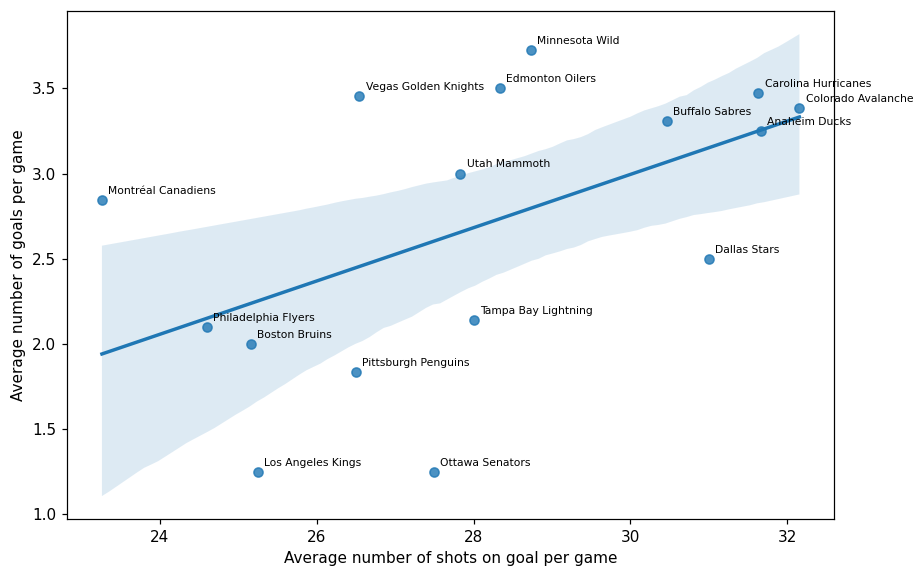

In [32]:
plt.figure(figsize=(9, 6))
sns.regplot(data=avgshots, x="Shot", y="Goal")
for team, row in avgshots.iterrows():
  plt.annotate(team, (row["Shot"], row["Goal"]), xytext=(4, 4), textcoords="offset points", fontsize=7)
plt.xlabel("Average number of shots on goal per game")
plt.ylabel("Average number of goals per game")
plt.show()

In [33]:
pearson = stats.pearsonr(avgshots["Shot"], avgshots["Goal"])
spearman = stats.spearmanr(avgshots["Shot"], avgshots["Goal"])
print(f"Корреляция Пирсона: {pearson.statistic:.3f}, p-value {pearson.pvalue:.3f}")
print(f"Корреляция Спирмена: {spearman.statistic:.3f}, p-value {spearman.pvalue:.3f}")
slope = stats.linregress(avgshots["Shot"], avgshots["Goal"])
print(f"Наклон прямой: {slope.slope:.3f} гола на дополнительный бросок, R^2 = {slope.rvalue ** 2:.2f}")
print(f"Доля голов среди бросков в створ по всему плей-офф: {on_goal_events['Goal'].mean():.3f}")

# отклонения команд от линии регрессии (в голах за игру)
(avgshots["Goal"] - (slope.intercept + slope.slope * avgshots["Shot"])).sort_values().round(2).rename("Residual")

Корреляция Пирсона: 0.521, p-value 0.039
Корреляция Спирмена: 0.578, p-value 0.019
Наклон прямой: 0.156 гола на дополнительный бросок, R^2 = 0.27
Доля голов среди бросков в створ по всему плей-офф: 0.105


Team Making the Play
Ottawa Senators        -1.35
Los Angeles Kings      -1.00
Dallas Stars           -0.65
Pittsburgh Penguins    -0.61
Tampa Bay Lightning    -0.54
Boston Bruins          -0.24
Philadelphia Flyers    -0.05
Anaheim Ducks          -0.01
Colorado Avalanche      0.05
Carolina Hurricanes     0.22
Buffalo Sabres          0.24
Utah Mammoth            0.34
Edmonton Oilers         0.77
Montréal Canadiens      0.90
Minnesota Wild          0.93
Vegas Golden Knights    1.00
Name: Residual, dtype: float64

Связь видна, хотя и не очень сильная: линия регрессии растёт, коэффициент корреляции Пирсона равен 0.52 (p ≈ 0.04), Спирмена - 0.58 (p ≈ 0.02). Наклон 0.16 выше средней результативности бросков (в плей-офф гол забивается примерно с 10.5% бросков в створ): команды с большим числом бросков в среднем ещё и реализуют их лучше. Но линия объясняет только около 27% разброса среднего числа голов, и многие команды заметно отклоняются от неё (см. таблицу отклонений): Vegas Golden Knights, Minnesota Wild, Montréal Canadiens и Edmonton Oilers забивают примерно на 0.8-1.0 гола за игру больше, чем «положено» по числу бросков, а Ottawa Senators (-1.35), Los Angeles Kings (-1.0), Dallas Stars и Pittsburgh Penguins - заметно меньше.

Такой результат ожидаем: число голов равно числу бросков, умноженному на долю реализации, а она сильно зависит от качества бросков (с какой точки и в какой момент они совершаются) и от вратаря соперника. Кроме того, у некоторых команд в выборке очень мало игр (Ottawa и Los Angeles - по 4), поэтому их положение на графике во многом случайно. Значит, большое число бросков помогает забивать, но само по себе не гарантирует результата.

### (14) Игра с наибольшим числом ударов по воротам

In [34]:
attempt_types = ["shot-on-goal", "goal", "missed-shot", "blocked-shot"]
attempts_per_game = events[events["Play Type"].isin(attempt_types)].groupby("Game ID").size()
print(f"Ударов в этой игре: {attempts_per_game.max()}")
gameInfo(attempts_per_game.idxmax())

Ударов в этой игре: 208


'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

Больше всего бросков (208, включая заблокированные и промахи) - в игре с двумя овертаймами, что объясняет рекорд: игра длилась заметно дольше обычных 60 минут.

В среднем в игре плей-офф совершается около 123 ударов (медиана 120), так что 208 - рекордное значение, заметно выше следующих за ним игр (169 и 163).

### (15) Броски в игре Carolina Hurricanes - Ottawa Senators

Рисуем площадку функцией `plot_rink` из `rink.py` и поверх неё - диаграмму рассеивания точек, откуда наносились броски, цвет точки показывает исход броска (`Play Type`), а форма маркера - команду: кружки у Carolina, крестики у Ottawa.

По условию удары гостей рисуем так, будто они бьют в левые ворота, а удары хозяев - в правые. В реальности команды меняют стороны каждый период, поэтому координаты нужно отразить, `(x, y) -> (-x, -y)`, в тех периодах, где хозяева защищают правые ворота (там хозяева «бьют влево», и без отражения нарушилось бы нужное правило). В этой игре это в точности нечётные периоды, как и сказано в задании, но в других играх сторона в первом периоде может быть другой, поэтому надёжнее ориентироваться на поле `Home Team's Defending Side`.

Заблокированные броски тоже включены: у них `Team Making the Play` - это команда, чей бросок заблокировали (проверено по составам на льду), а координаты показывают место блока.

In [35]:
game_id = attempts_per_game.idxmax()
game_attempts = events[(events["Game ID"] == game_id) & events["Play Type"].isin(attempt_types)].copy()

flip = game_attempts["Home Team's Defending Side"] == "right"
game_attempts["x"] = np.where(flip, -game_attempts["X Coordinate on the Ice Rink"], game_attempts["X Coordinate on the Ice Rink"])
game_attempts["y"] = np.where(flip, -game_attempts["Y Coordinate on the Ice Rink"], game_attempts["Y Coordinate on the Ice Rink"])

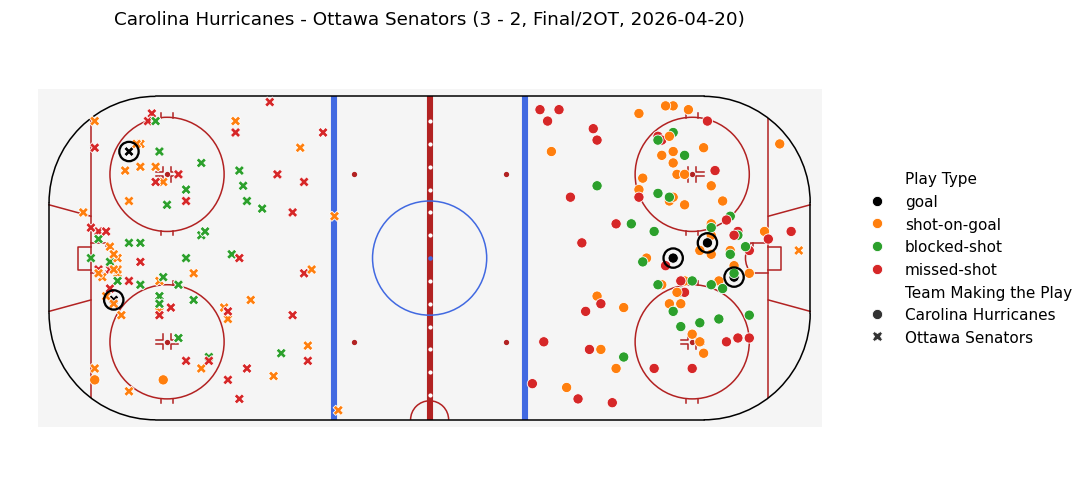

In [36]:
outcome_order = ["goal", "shot-on-goal", "blocked-shot", "missed-shot"]
outcome_palette = {"goal": "black", "shot-on-goal": "tab:orange", "blocked-shot": "tab:green", "missed-shot": "tab:red"}

plt.figure(figsize=(10, 4.6))
plot_rink()
sns.scatterplot(data=game_attempts, x="x", y="y", hue="Play Type", style="Team Making the Play", hue_order=outcome_order, palette=outcome_palette, s=45)
goals_only = game_attempts[game_attempts["Play Type"] == "goal"]
plt.scatter(goals_only["x"], goals_only["y"], s=160, facecolors="none", edgecolors="black", linewidths=1.5)
plt.axis("equal")
plt.axis("off")
plt.title(gameInfo(game_id))
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

Картина согласуется с хоккейной логикой: броски хозяев (круги) сосредоточены перед правыми воротами, гостей (крестики) - перед левыми; основная масса бросков - из «домика» перед воротами и из зон вбрасывания, голы (чёрные, обведены) - все из ближней зоны. Заблокированные броски (зелёные) в основном тоже лежат в атакующей зоне, ближе к воротам и в «домике»; промахи (красные) разбросаны шире, включая дальние точки у синей линии.

## Задания без подсказок

Для топ-10 используем `nlargest(10, column, keep="all")`: если на 10-м месте несколько игроков с одинаковым значением, в список попадают все, поэтому строк может быть больше десяти.

Для показателей «за игру» нужно число игр, сыгранных игроком. Берём игры, в которых фамилия игрока встречается хотя бы раз в составе на льду (`games_played`). Любой игрок из граф `Player in the Event` есть и в составе на льду в той же игре (проверено).

In [37]:
goal_events = events[events["Play Type"] == "goal"]

ice_columns = [c for c in events.columns if "Player on the Ice" in c or c.endswith("Goalie")]
player_games = (
  events[["Game ID"] + ice_columns]
  .melt(id_vars="Game ID", value_name="Player")
  .dropna(subset=["Player"])[["Game ID", "Player"]]
  .drop_duplicates()
)
games_played = player_games.groupby("Player").size().rename("Games")

### (16) Больше всего голов

In [38]:
goals_by_player = goal_events["Player in the Event #1"].value_counts().rename("Goals").to_frame()
goals_by_player.nlargest(10, "Goals", keep="all")

,Goals
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Nikolaj Ehlers,8
Jordan Staal,8
Alex Newhook,7
Taylor Hall,7
Jackson Blake,7


Лидер - Brett Howden (14 голов), за ним Pavel Dorofeyev (12), Logan Stankoven (11) и Mitch Marner (10). На 7 голах остановились сразу шесть игроков, поэтому в списке 12 строк.

### (17) Больше всего голевых передач

Передачи - это игроки в графах `Player in the Event #2` и `#3` для голов.

In [39]:
assists_by_player = pd.concat([goal_events["Player in the Event #2"], goal_events["Player in the Event #3"]]).value_counts().rename("Assists").to_frame()
assists_by_player.nlargest(10, "Assists", keep="all")

,Assists
Jack Eichel,20
Mitch Marner,19
Lane Hutson,13
Jackson Blake,13
Nick Suzuki,12
Taylor Hall,12
Martin Necas,12
Shea Theodore,12
Kirill Kaprizov,11
Quinn Hughes,11


С большим отрывом лидируют Jack Eichel (20 передач) и Mitch Marner (19), у остальных не больше 13.

### (18) Больше всего очков (гол + пас)

In [40]:
points = goals_by_player.join(assists_by_player, how="outer").fillna(0).astype(int)
points["Points"] = points["Goals"] + points["Assists"]
points.nlargest(10, "Points", keep="all")

,Goals,Assists,Points
Player in the Event #1,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Lane Hutson,3,13,16
Logan Stankoven,11,5,16


Лидер по очкам - Mitch Marner (29 = 10 голов + 19 передач), второй - Jack Eichel (22) почти целиком за счёт передач (2 гола), а Brett Howden, лучший по голам, набрал 18 очков (14 + 4). На 16 очках четыре игрока, поэтому в списке 11 строк.

### (19) Больше всего бросков в створ в среднем за игру

Бросок в створ - это `shot-on-goal` или `goal`, бросающий - `Player in the Event #1`. Делим число бросков игрока на число сыгранных им игр.

Показатель «в среднем за игру» чувствителен к малой выборке: игрок, выходивший на лёд в одной-двух играх, может случайно оказаться наверху. Поэтому приводим два списка: по всем игрокам, как просили, и только по игрокам, сыгравшим не менее 6 игр (медианное число игр у игрока в данных).

In [41]:
shots_on_goal_by_player = events[events["Play Type"].isin(["shot-on-goal", "goal"])]["Player in the Event #1"].value_counts().rename("Shots on Goal")
shot_rate = pd.concat([shots_on_goal_by_player, games_played], axis=1, join="inner")
shot_rate["Shots per Game"] = (shot_rate["Shots on Goal"] / shot_rate["Games"]).round(2)
shot_rate.nlargest(10, "Shots per Game", keep="all")

,Shots on Goal,Games,Shots per Game
Jason Robertson,30,6,5.00
Dylan Guenther,27,6,4.50
Nikita Kucherov,31,7,4.43
Matt Boldy,48,11,4.36
Quinton Byfield,17,4,4.25
Darren Raddysh,28,7,4.00
Joel Eriksson Ek,24,6,4.00
Alex Laferriere,15,4,3.75
David Pastrnak,22,6,3.67
Nathan MacKinnon,47,13,3.62


In [42]:
# только игроки, сыгравшие не менее 6 игр
shot_rate[shot_rate["Games"] >= 6].nlargest(10, "Shots per Game", keep="all")

,Shots on Goal,Games,Shots per Game
Jason Robertson,30,6,5.00
Dylan Guenther,27,6,4.50
Nikita Kucherov,31,7,4.43
Matt Boldy,48,11,4.36
Darren Raddysh,28,7,4.00
Joel Eriksson Ek,24,6,4.00
David Pastrnak,22,6,3.67
Nathan MacKinnon,47,13,3.62
Tage Thompson,46,13,3.54
Rasmus Dahlin,46,13,3.54


### (20) Больше всего силовых приёмов в среднем за игру

Силовой приём - событие `hit`, игрок, проводящий приём, - `Player in the Event #1`. Так же приводим два списка (по всем игрокам и по игрокам, сыгравшим не менее 6 игр).

In [43]:
hits_by_player = events[events["Play Type"] == "hit"]["Player in the Event #1"].value_counts().rename("Hits")
hit_rate = pd.concat([hits_by_player, games_played], axis=1, join="inner")
hit_rate["Hits per Game"] = (hit_rate["Hits"] / hit_rate["Games"]).round(2)
hit_rate.nlargest(10, "Hits per Game", keep="all")

,Hits,Games,Hits per Game
Lawson Crouse,38,6,6.33
Alex Turcotte,6,1,6.00
Alexander Petrovic,6,1,6.00
Yakov Trenin,51,9,5.67
Dylan Cozens,22,4,5.50
Vasily Podkolzin,32,6,5.33
Ivan Barbashev,110,22,5.00
Marcus Foligno,55,11,5.00
Carl Grundstrom,15,3,5.00
Owen Tippett,29,6,4.83


In [44]:
hit_rate[hit_rate["Games"] >= 6].nlargest(10, "Hits per Game", keep="all")

,Hits,Games,Hits per Game
Lawson Crouse,38,6,6.33
Yakov Trenin,51,9,5.67
Vasily Podkolzin,32,6,5.33
Ivan Barbashev,110,22,5.00
Marcus Foligno,55,11,5.00
Owen Tippett,29,6,4.83
William Carrier,91,19,4.79
Cole Smith,100,22,4.55
Jordan Staal,86,19,4.53
MacKenzie Weegar,26,6,4.33


**К пунктам (19) и (20).** В списках «по всем игрокам» заметны игроки с одной-двумя играми, у которых показатель большой лишь потому, что знаменатель маленький (например, один игрок с шестью приёмами за единственную игру). Во втором списке (не менее 6 игр) картина устойчивее: это те игроки, которые регулярно играют и много бросают или много бьют соперников. Если нужен надёжный рейтинг, стоит смотреть именно на второй вариант.

Конкретно: в обоих списках по броскам лидирует Jason Robertson (5.0 за 6 игр), за ним Dylan Guenther (4.5) и Nikita Kucherov (4.43). Quinton Byfield (4.25 за 4 игры) и Alex Laferriere (3.75) есть только в списке по всем игрокам. По приёмам лидирует Lawson Crouse (6.33 за 6 игр), а Alex Turcotte и Alexander Petrovic с шестью приёмами в единственной игре (6.0) остаются только в первом списке. Самый стабильный силовой игрок - Ivan Barbashev: 110 приёмов за 22 игры (5.0 за игру).

### (21) Вратари, которые хотя бы в одном матче не пропустили ни одного гола

Алгоритм:
1. Собираем пары (игра, вратарь) из столбцов `Away Team's Goalie` и `Home Team's Goalie`: вратарь попадает в пару, если он хотя бы в одном событии игры указан как вратарь на льду. Это включает вратарей, которые вышли на замену или были заменены.
2. Для каждого гола смотрим, какая команда забила, и приписываем гол вратарю соперника, который был на льду в предыдущем событии (состояние до гола, см. вспомогательный пункт перед пунктом 9: строка самого гола показывает состав уже после гола, и у победных голов в овертайме вратарей там нет вообще). Если перед голом вратаря не было (ворота пустые), гол никому не приписывается: таких голов 34.
3. Оставляем пары, где пропущено 0 голов.

Дополнительно считаем «полные сухие матчи»: соперник за всю игру не забил (итоговый счёт 0) и вратарь был единственным у своей команды.

In [45]:
away_goalies = events[["Game ID", "Away Team", "Away Team's Goalie"]].set_axis(["Game ID", "Team", "Goalie"], axis=1)
home_goalies = events[["Game ID", "Home Team", "Home Team's Goalie"]].set_axis(["Game ID", "Team", "Goalie"], axis=1)
goalie_games = pd.concat([away_goalies, home_goalies]).dropna(subset=["Goalie"]).drop_duplicates()

goals_against = goal_events.copy()
goals_against["Goalie"] = np.where(
  goals_against["Team Making the Play"] == goals_against["Home Team"],
  goals_against["Previous Away Goalie"],
  goals_against["Previous Home Goalie"],
)
print(f"Голов в пустые ворота: {goals_against['Goalie'].isna().sum()}")

conceded = goals_against.dropna(subset=["Goalie"]).groupby(["Game ID", "Goalie"]).size().rename("Conceded").reset_index()
goalie_games = goalie_games.merge(conceded, on=["Game ID", "Goalie"], how="left").fillna({"Conceded": 0})

# полные сухие матчи: соперник забил 0 и вратарь единственный у команды
goalie_games = goalie_games.merge(games[["Away Team", "Home Team", "Away Score", "Home Score"]].reset_index(), on="Game ID")
goalie_games["Opponent Score"] = np.where(goalie_games["Team"] == goalie_games["Home Team"], goalie_games["Away Score"], goalie_games["Home Score"])
goalies_in_team_game = goalie_games.groupby(["Game ID", "Team"])["Goalie"].transform("nunique")
goalie_games["Full Shutout"] = (goalie_games["Opponent Score"] == 0) & (goalies_in_team_game == 1)

shutouts = goalie_games[goalie_games["Conceded"] == 0]
empty_net_goals = int(goals_against["Goalie"].isna().sum())
print(f"Пар (игра, вратарь): {len(goalie_games)}")
print(f"Из них без пропущенных голов: {len(shutouts)}")
print(f"Голы вратарям + голы в пустые ворота: {int(goalie_games['Conceded'].sum()) + empty_net_goals}")
print(f"Всего голов: {len(goals_against)}")
shutouts[["Game ID", "Goalie", "Team", "Full Shutout"]]

Голов в пустые ворота: 34
Пар (игра, вратарь): 174
Из них без пропущенных голов: 11
Голы вратарям + голы в пустые ворота: 486
Всего голов: 486


,Game ID,Goalie,Team,Full Shutout
11,2025030126,Andrei Vasilevskiy,Tampa Bay Lightning,True
18,2025030142,Dan Vladar,Philadelphia Flyers,True
52,2025030216,Ukko-Pekka Luukkonen,Buffalo Sabres,False
73,2025030314,Frederik Andersen,Carolina Hurricanes,True
85,2025030416,Brandon Bussi,Carolina Hurricanes,True
88,2025030112,Alex Lyon,Buffalo Sabres,False
91,2025030114,Joonas Korpisalo,Boston Bruins,False
101,2025030131,Frederik Andersen,Carolina Hurricanes,True
110,2025030146,Dan Vladar,Philadelphia Flyers,True
142,2025030221,Frederik Andersen,Carolina Hurricanes,True


In [46]:
shutout_goalies = shutouts.groupby("Goalie").agg(Team=("Team", "first"), Games=("Game ID", "count"), Full_Shutouts=("Full Shutout", "sum"))
shutout_goalies.sort_values(["Games", "Full_Shutouts"], ascending=False)

,Team,Games,Full_Shutouts
Goalie,,,
Frederik Andersen,Carolina Hurricanes,3,3
Dan Vladar,Philadelphia Flyers,2,2
Andrei Vasilevskiy,Tampa Bay Lightning,1,1
Brandon Bussi,Carolina Hurricanes,1,1
Alex Lyon,Buffalo Sabres,1,0
Joonas Korpisalo,Boston Bruins,1,0
Scott Wedgewood,Colorado Avalanche,1,0
Ukko-Pekka Luukkonen,Buffalo Sabres,1,0


In [47]:
# проверка 1: число игр, где одна из команд вообще не забила, должно совпасть с числом полных сухих матчей
print(f"Игр, где одна из команд не забила: {((games['Away Score'] == 0) | (games['Home Score'] == 0)).sum()}")
print(f"Полных сухих матчей: {goalie_games['Full Shutout'].sum()}")

# проверка 2: результат не зависит от того, как поступить с голами в пустые ворота. Если приписать
# их последнему вратарю, который был в воротах до того, как его сняли, список не меняется
for side in ["Away", "Home"]:
  events[f"Last {side} Goalie"] = events.groupby("Game ID")[f"{side} Team's Goalie"].ffill()
  events[f"Previous Last {side} Goalie"] = events.groupby("Game ID")[f"Last {side} Goalie"].shift(1)
alt_goals = events[events["Play Type"] == "goal"].copy()
alt_goals["Goalie"] = np.where(alt_goals["Team Making the Play"] == alt_goals["Home Team"], alt_goals["Previous Last Away Goalie"], alt_goals["Previous Last Home Goalie"])
alt_conceded = alt_goals.groupby(["Game ID", "Goalie"]).size().rename("Conceded Alt").reset_index()
alt_games = goalie_games.merge(alt_conceded, on=["Game ID", "Goalie"], how="left").fillna({"Conceded Alt": 0})
alt_shutouts = alt_games[alt_games["Conceded Alt"] == 0]
print(f"Список не меняется: {set(zip(alt_shutouts['Game ID'], alt_shutouts['Goalie'])) == set(zip(shutouts['Game ID'], shutouts['Goalie']))}")

Игр, где одна из команд не забила: 7
Полных сухих матчей: 7
Список не меняется: True


**Результат.** Таких вратарей восемь (см. таблицу). Четверо из них отстояли «на ноль» полные матчи: в сумме это 7 матчей, ровно столько игр, где одна из команд не забила ни разу (проверка выше). Остальные четверо выходили на замену или были заменены и за время на льду не пропустили ни одного гола, то есть «сухими» были только отрезки игры, как и подразумевалось в условии.

Здесь же видно, почему важно брать состав до гола, а не из строки гола: если брать вратаря из самой строки гола, то голы в овертайме (их 22, и у них оба вратаря отсутствуют) никому не засчитываются, и в список ошибочно попали бы вратари, которые на самом деле пропустили победный гол в овертайме.

### (22) Свой вопрос: насколько важен первый гол в матче?

**Вопрос.** Как часто выигрывает команда, забившая первой, и зависит ли это от того, играет она дома или в гостях? Заодно проверим, есть ли в этом плей-офф «домашнее преимущество».

**Как проверяем.**
1. Для каждой игры находим первый гол: сортируем голы по номеру события внутри игры (`Play ID`) и берём первый.
2. Победитель - команда с большим итоговым счётом (из `games`).
3. Считаем долю игр, где первая забившая команда выиграла, и доверительный интервал Уилсона для этой доли. Нулевая гипотеза - что первый гол ничего не значит и доля равна 50% (точный биномиальный тест).
4. Отдельно смотрим на долю по месту (первый гол забили дома/в гостях) и по типу игры (основное время / овертайм), а также на долю домашних побед.

In [48]:
first_goals = goal_events.sort_values(["Game ID", "Play ID"]).groupby("Game ID").first()

first_goal_stats = games[["Away Team", "Home Team", "Away Score", "Home Score", "Outcome"]].copy()
first_goal_stats["First Scorer"] = first_goals["Team Making the Play"]
first_goal_stats["Winner"] = np.where(first_goal_stats["Home Score"] > first_goal_stats["Away Score"], first_goal_stats["Home Team"], first_goal_stats["Away Team"])
first_goal_stats["First Scorer Won"] = first_goal_stats["First Scorer"] == first_goal_stats["Winner"]
first_goal_stats["First Scorer Is Home"] = first_goal_stats["First Scorer"] == first_goal_stats["Home Team"]
first_goal_stats["Overtime"] = first_goal_stats["Outcome"] != "Final"

def share_with_ci(wins: pd.Series) -> pd.Series:
  k, n = int(wins.sum()), len(wins)
  ci = stats.binomtest(k, n, 0.5).proportion_ci(confidence_level=0.95, method="wilson")
  return pd.Series({"Wins": k, "Games": n, "Share": k / n, "CI low": ci.low, "CI high": ci.high})

result = pd.DataFrame({
  "Все игры": share_with_ci(first_goal_stats["First Scorer Won"]),
  "Первый гол у хозяев": share_with_ci(first_goal_stats[first_goal_stats["First Scorer Is Home"]]["First Scorer Won"]),
  "Первый гол у гостей": share_with_ci(first_goal_stats[~first_goal_stats["First Scorer Is Home"]]["First Scorer Won"]),
  "Основное время": share_with_ci(first_goal_stats[~first_goal_stats["Overtime"]]["First Scorer Won"]),
  "Овертайм": share_with_ci(first_goal_stats[first_goal_stats["Overtime"]]["First Scorer Won"]),
}).T
result.round(3)

,Wins,Games,Share,CI low,CI high
Все игры,56.0,82.0,0.683,0.576,0.774
Первый гол у хозяев,24.0,35.0,0.686,0.520,0.814
Первый гол у гостей,32.0,47.0,0.681,0.538,0.796
Основное время,44.0,60.0,0.733,0.610,0.829
Овертайм,12.0,22.0,0.545,0.347,0.731


Первая забившая команда выиграла 56 из 82 игр (68.3%), p-value биномиального теста против 50%: 0.0012
Хозяева выиграли 39 из 82 игр (47.6%), p-value против 50%: 0.74


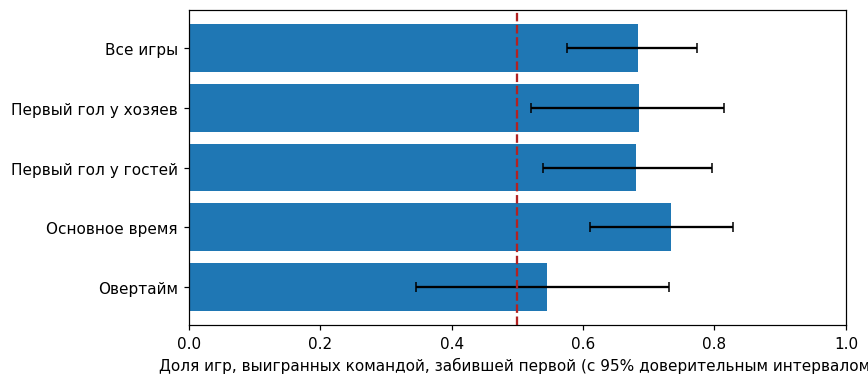

In [49]:
k, n = int(first_goal_stats["First Scorer Won"].sum()), len(first_goal_stats)
print(f"Первая забившая команда выиграла {k} из {n} игр ({k / n:.1%}), p-value биномиального теста против 50%: {stats.binomtest(k, n, 0.5).pvalue:.4f}")

home_wins = int((first_goal_stats["Home Score"] > first_goal_stats["Away Score"]).sum())
print(f"Хозяева выиграли {home_wins} из {n} игр ({home_wins / n:.1%}), p-value против 50%: {stats.binomtest(home_wins, n, 0.5).pvalue:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(result.index[::-1], result["Share"][::-1], color="tab:blue")
ax.errorbar(result["Share"][::-1], result.index[::-1], xerr=[(result["Share"] - result["CI low"])[::-1], (result["CI high"] - result["Share"])[::-1]], fmt="none", ecolor="black", capsize=3)
ax.axvline(0.5, color="firebrick", linestyle="--")
ax.set_xlim(0, 1)
ax.set_xlabel("Доля игр, выигранных командой, забившей первой (с 95% доверительным интервалом)")
plt.tight_layout()
plt.show()

**Ответ.** Команда, забившая первой, выиграла 56 из 82 игр - это 68.3% (95% доверительный интервал 57.6-77.4%), и точный биномиальный тест уверенно отвергает гипотезу «первый гол ничего не значит» (p ≈ 0.001). То есть открыть счёт - серьёзное преимущество, но не приговор: в 26 играх команда, пропустившая первой, всё же выиграла.

Преимущество одинаково для хозяев и гостей (68.6% и 68.1%), так что от места игры оно не зависит. В играх, дошедших до овертайма, картина другая: доля составляет всего 54.5% (12 из 22), а интервал очень широк, что логично: такие игры по определению были равными (в основное время закончились вничью), и первый гол в них значит меньше. А вот в играх, закончившихся в основное время, доля выше (около 73%, 44 из 60).

И ещё одно наблюдение: домашнего преимущества в этом плей-офф не видно - хозяева выиграли 39 из 82 игр (47.6%, p ≈ 0.74), то есть примерно половину.

**Оговорка.** Это корреляция, а не причинно-следственная связь: сильная команда и первой забивает чаще, и выигрывает чаще, так что часть эффекта объясняется просто разницей в классе команд; кроме того, 82 игры - не очень большая выборка.

## Итоги

- Данные: 82 игры плей-офф, 29710 событий; в среднем за игру забивается 5.9 шайбы (дисперсия 5.1 - как у распределения Пуассона), 22 игры дошли до овертайма.
- Дальние броски (дальше 100 футов) в основном оказываются точными из-за того, как фиксируются события (промахи со своей половины записываются как проброс шайбы, а не как бросок), а не потому, что их легче забить.
- Доля точных бросков у всех команд примерно одинакова (около 64%) и не отличает победителей от проигравших; число бросков в створ связано с числом голов умеренно (r ≈ 0.52).
- Первый гол в матче даёт заметное преимущество (68% побед), а домашнего льда в этом плей-офф в данных не видно.